In [ ]:
import torch 
import torch.nn as nn 
from transformer.model import GPT 


model = GPT(
    vocab_size=20,
    context_length=8,
    embedding_dim=16,
    num_heads=4,
    num_layers=2
)

token_ids = torch.randint(0, 20, (3, 5))
logits = model(token_ids)

print("Input:", token_ids.shape)
print("Logits:", logits.shape)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

model.zero_grad()

token_ids = torch.randint(0, 20, (3, 5))
targets = torch.randint(0, 20, (3, 5))

logits = model(token_ids)

loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(
    logits.reshape(-1, 20),
    targets.reshape(-1)
)

loss.backward()

print("Loss:", loss.item())
print("Token embedding gradient exists:",
      model.token_embedding.embedding.weight.grad is not None)
print("Attention Q gradient exists:",
      model.blocks[0].mha.q_proj.weight.grad is not None)
print("MLP gradient exists:",
      model.blocks[0].mlp.fc1.weight.grad is not None)
print("LM head gradient exists:",
      model.lm_head.projection.weight.grad is not None)

Input: torch.Size([3, 5])
Logits: torch.Size([3, 5, 20])
Total parameters: 7360
Loss: 3.0019800662994385
Token embedding gradient exists: True
Attention Q gradient exists: True
MLP gradient exists: True
LM head gradient exists: True


In [2]:
from tokenizer import Tokeniser

tokenizer = Tokeniser("hello world")

ids = tokenizer.encode("hello")
print(ids)
print(tokenizer.decode(ids))
print("Vocabulary size:", tokenizer.vocab_size)

assert tokenizer.decode(tokenizer.encode("hello")) == "hello"
assert tokenizer.vocab_size == len(set("hello world"))

try:
    tokenizer.encode("hello!")
except ValueError as e:
    print(e)

print("All tests passed.")


[3, 2, 4, 4, 5]
hello
Vocabulary size: 8
Unknown character: '!'
All tests passed.


In [ ]:
from transformer.batching import get_batch
from pathlib import Path
from transformer.tokenizer import Tokeniser
import torch

batch_size = 4
context_length = 8
text = Path("data/tiny-shakespeare.txt").read_text(encoding="utf-8")
tokenizer = Tokeniser(text)
encoded = tokenizer.encode(text)
data = torch.tensor(encoded, dtype=torch.long)

x, y = get_batch(data, batch_size, context_length)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Input:\n", x)
print("Target:\n", y)

print("Decoded input:", tokenizer.decode(x[0].tolist()))
print("Decoded target:", tokenizer.decode(y[0].tolist()))

assert x.shape == (4, 8)
assert y.shape == (4, 8)
assert torch.equal(x[:, 1:], y[:, :-1])

print("Batch tests passed!")


Input shape: torch.Size([4, 8])
Target shape: torch.Size([4, 8])
Input:
 tensor([[21, 26, 19, 14, 30, 27, 23, 17],
        [39, 57, 58,  1, 39, 50, 50,  1],
        [ 0, 27, 52,  1, 54, 59, 56, 54],
        [ 0, 35, 46, 39, 58,  1, 50, 43]])
Target:
 tensor([[26, 19, 14, 30, 27, 23, 17, 10],
        [57, 58,  1, 39, 50, 50,  1, 58],
        [27, 52,  1, 54, 59, 56, 54, 53],
        [35, 46, 39, 58,  1, 50, 43, 57]])
Decoded input: INGBROKE
Decoded target: NGBROKE:
Batch tests passed!


In [4]:

import torch
import torch.nn as nn
from transformer.model import GPT

batch_size = 4
context_length = 8

x, y = get_batch(data, batch_size, context_length)

model = GPT(
    vocab_size=tokenizer.vocab_size,
    context_length=context_length,
    embedding_dim=32,
    num_heads=4,
    num_layers=2
)

logits = model(x)

loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(
    logits.reshape(-1, tokenizer.vocab_size),
    y.reshape(-1)
)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

optimizer.zero_grad()
loss.backward()
optimizer.step()

print("One optimization step completed.")

Logits shape: torch.Size([4, 8, 65])
Loss: 4.643787860870361
One optimization step completed.


In [7]:
from pathlib import Path
from transformer.bpe import BPETokeniser

text = Path("data/tiny-shakespeare.txt").read_text(encoding="utf-8")

tokeniser = BPETokeniser(text, num_merges=500)

encoded = tokeniser.encode(text)

print("Original characters:", len(text))
print("Character vocabulary:", len(set(text)))
print("BPE vocabulary:", tokeniser.vocab_size)
print("Encoded tokens:", len(encoded))
print("Characters per token:", len(text) / len(encoded))

assert tokeniser.decode(encoded) == text

Original characters: 1115394
Character vocabulary: 65
BPE vocabulary: 565
Encoded tokens: 490609
Characters per token: 2.273488664088918


In [ ]:
from pathlib import Path
from transformer.bpe import BPETokeniser

text = Path("data/tiny-shakespeare.txt").read_text(encoding="utf-8")

tokeniser = BPETokeniser(text, num_merges=500)

encoded = tokeniser.encode(text)

print("Original characters:", len(text))
print("Character vocabulary:", len(set(text)))
print("BPE vocabulary:", tokeniser.vocab_size)
print("Encoded tokens:", len(encoded))
print("Characters per token:", len(text) / len(encoded))

assert tokeniser.decode(encoded) == text

Original characters: 1115394
Character vocabulary: 65
BPE vocabulary: 565
Encoded tokens: 490609
Characters per token: 2.273488664088918


In [3]:
import torch
from transformer.model import GPT

checkpoint = torch.load(
    "checkpoints/best_gpt_bpe.pt",
    map_location="cpu",
    weights_only=True
)

model = GPT(
    vocab_size=checkpoint["vocab_size"],
    context_length=checkpoint["context_length"],
    embedding_dim=checkpoint["embedding_dim"],
    num_heads=checkpoint["num_heads"],
    num_layers=checkpoint["num_layers"]
)


model.load_state_dict(checkpoint["model_state_dict"])
print("Model loaded")

model.eval()

token_ids = torch.randint(
    0,
    checkpoint["vocab_size"],
    (1, 12)
)

with torch.no_grad():
    logits = model(token_ids)


for name, module in model.named_modules():
    if hasattr(module, "last_attention_weights"):
        weights = module.last_attention_weights

        print(name, weights.shape)
        print("Row sums:", weights[0, 0].sum(dim=-1))
        print("Future attention:", weights[0, 0].triu(diagonal=1))

Model loaded
blocks.0.mha torch.Size([1, 4, 12, 12])
Row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000])
Future attention: tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])
blocks.1.mha torch.Size([1, 4, 12, 12])
Row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0

In [4]:
import torch
from transformer.model import GPT
from transformer.bpe import BPETokeniser

CHECKPOINT_PATH = "checkpoints/best_gpt_bpe.pt"
TOKENISER_PATH = "checkpoints/bpe_tokeniser.json"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

tokenizer = BPETokeniser.load(TOKENISER_PATH)

model = GPT(
    vocab_size=checkpoint["vocab_size"],
    context_length=checkpoint["context_length"],
    embedding_dim=checkpoint["embedding_dim"],
    num_heads=checkpoint["num_heads"],
    num_layers=checkpoint["num_layers"]
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Tokenizer loaded:", tokenizer.vocab_size)
print("Model loaded")

Tokenizer loaded: 565
Model loaded


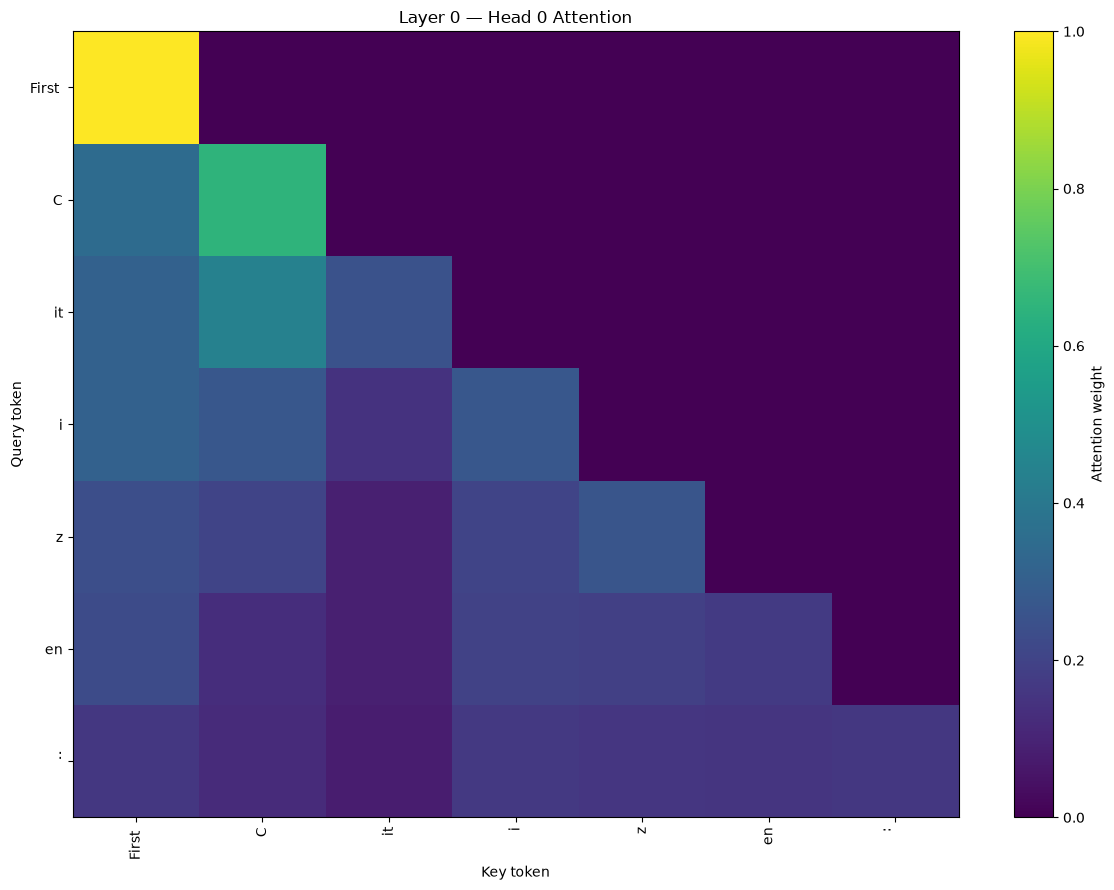

In [8]:
import matplotlib.pyplot as plt

prompt = "First Citizen:\n"
token_ids = tokenizer.encode(prompt)

x = torch.tensor(
    [token_ids],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    logits = model(x)

attention = (
    model.blocks[0].mha.last_attention_weights[0, 0]
    .cpu()
    .numpy()
)

tokens = [tokenizer.int2token[token_id] for token_id in token_ids]

plt.figure(figsize=(12, 9))
plt.imshow(attention, cmap="viridis", aspect="auto")
plt.colorbar(label="Attention weight")

plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)

plt.xlabel("Key token")
plt.ylabel("Query token")
plt.title("Layer 0 — Head 0 Attention")
plt.tight_layout()
plt.show()

In [6]:
prompt = "First Citizen:\n"
token_ids = tokenizer.encode(prompt)

x = torch.tensor(
    [token_ids],
    dtype=torch.long,
    device=device
)

model.eval()

with torch.no_grad():
    logits = model(x)

print("Forward pass complete.")
print("Logits shape:", logits.shape)
print("Attention shape:", model.blocks[0].mha.last_attention_weights.shape)

Forward pass complete.
Logits shape: torch.Size([1, 7, 565])
Attention shape: torch.Size([1, 4, 7, 7])


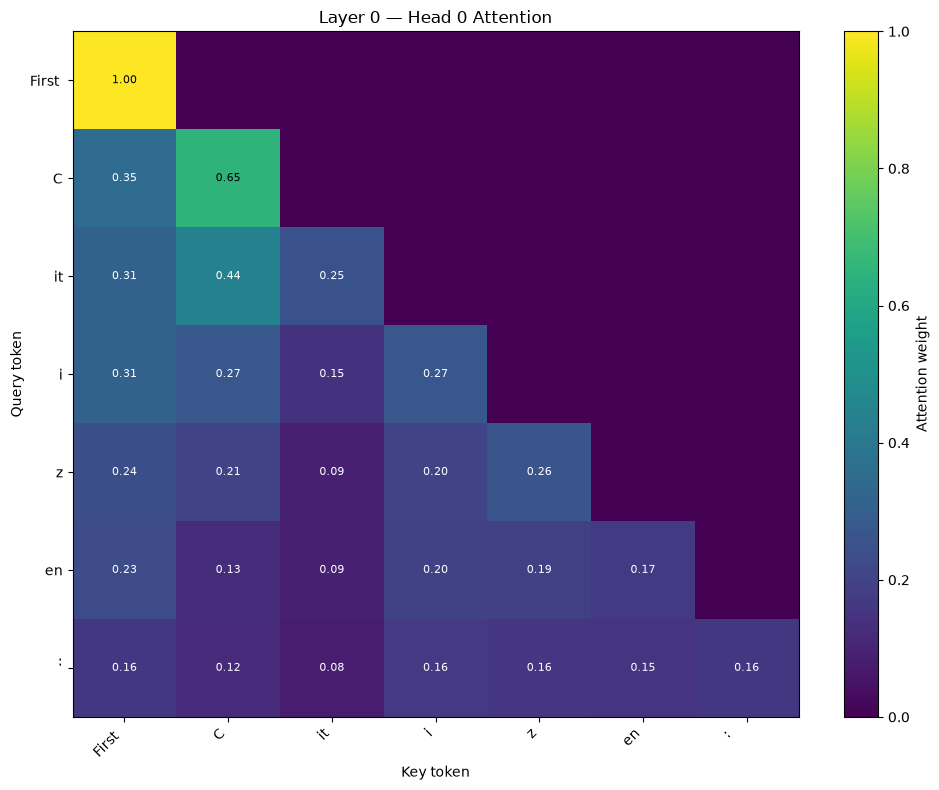

In [7]:

import matplotlib.pyplot as plt
import numpy as np

layer_idx = 0
head_idx = 0

weights = model.blocks[layer_idx].mha.last_attention_weights
attention = weights[0, head_idx].cpu().numpy()

tokens = [tokenizer.int2token[token_id] for token_id in token_ids]

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    attention,
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(tokens)))
ax.set_xticklabels(tokens, rotation=45, ha="right")
ax.set_yticks(range(len(tokens)))
ax.set_yticklabels(tokens)

for i in range(len(tokens)):
    for j in range(len(tokens)):
        if attention[i, j] > 0:
            ax.text(
                j, i, f"{attention[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if attention[i, j] < 0.5 else "black"
            )

ax.set_xlabel("Key token")
ax.set_ylabel("Query token")
ax.set_title(f"Layer {layer_idx} — Head {head_idx} Attention")

fig.colorbar(image, ax=ax, label="Attention weight")
fig.tight_layout()
plt.show()


In [ ]:
from transformer.observatory import inspect_model

result = inspect_model(
    model=model,
    tokenizer=tokenizer,
    prompt="First Citizen:\n",
    device=device
)

print("Tokens:", result["tokens"])
print("Token IDs:", result["token_ids"])
print("\nAttention shapes:")
for layer_idx, weights in enumerate(result["attention_weights"]):
    print(f"Layer {layer_idx}: {weights.shape}")

print("\nTop next-token predictions:")
for prediction in result["top_predictions"]:
    print(
        repr(prediction["token"]),
        f'{prediction["probability"]:.4f}'
    )

Tokens: ['First ', 'C', 'it', 'i', 'z', 'en', ':\n']
Token IDs: [510, 15, 122, 47, 64, 79, 77]

Attention shapes:
Layer 0: torch.Size([4, 7, 7])
Layer 1: torch.Size([4, 7, 7])

Top next-token predictions:
'Wh' 0.0681
'G' 0.0653
'M' 0.0618
'B' 0.0551
'C' 0.0549
'T' 0.0541
'L' 0.0527
'My ' 0.0457
'The ' 0.0388
'You' 0.0379


C:\Users\nimes.DESKTOP-L78OJ71\AppData\Local\Temp\ipykernel_11828\765303042.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  attention_fig.show()


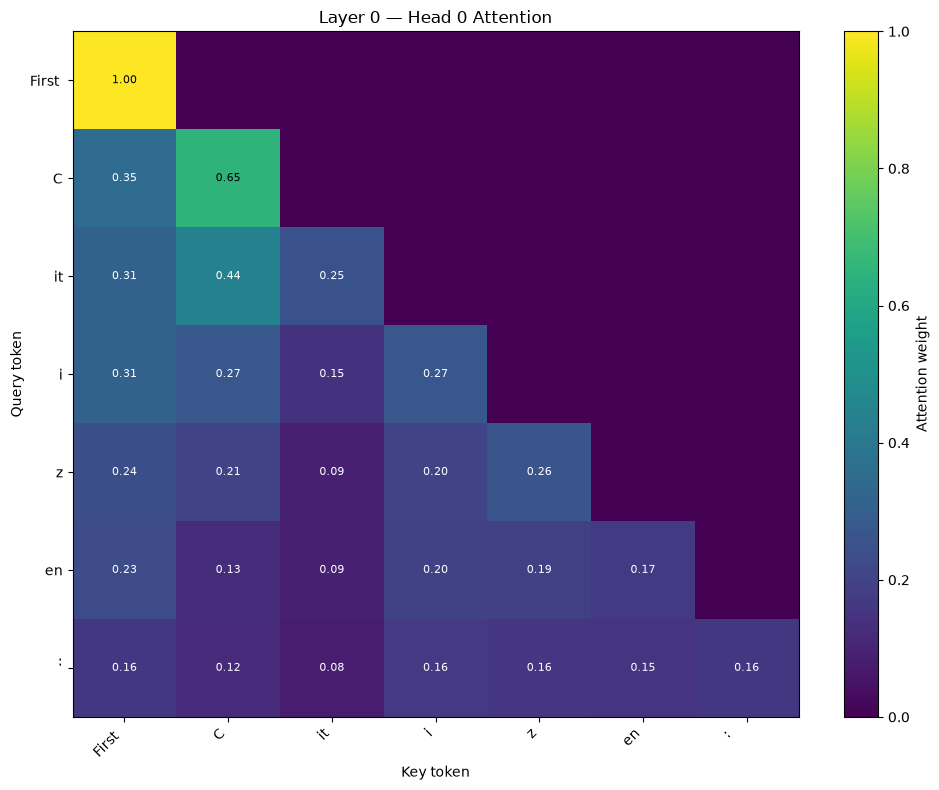

In [9]:
from transformer.visualization import plot_attention, plot_predictions

attention_fig = plot_attention(
    result,
    layer_idx=0,
    head_idx=0
)

attention_fig.show()

C:\Users\nimes.DESKTOP-L78OJ71\AppData\Local\Temp\ipykernel_11828\3098262069.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  prediction_fig.show()


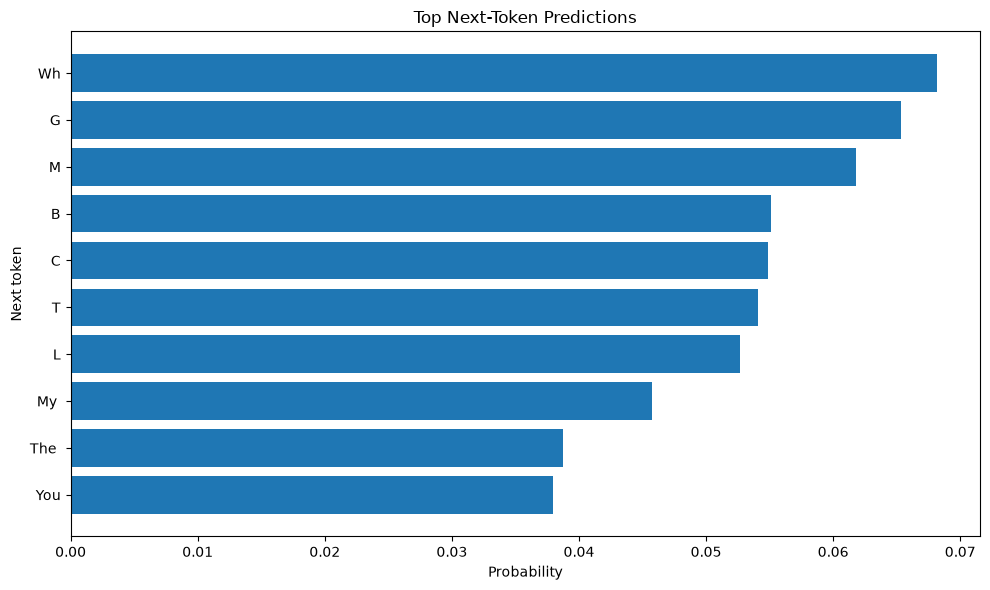

: 

In [ ]:
prediction_fig = plot_predictions(result, top_k=10)
prediction_fig.show()